In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

# ACS 1 Exploratory Data Analysis

In [2]:
acs1_combined = pd.read_csv("demographic_processed/acs1_combined.csv")
print(acs1_combined.to_string())

     YEAR         COUNTY  COUNTY_FIPS    TOTAL   WHITE   BLACK  NATIVE AMERICAN   ASIAN  PACIFIC ISLANDER   OTHER
0    2010        Alameda         6001  1513952  692377  186016             7819  400567             12058  299551
1    2010   Contra Costa         6013  1052827  675793   97476             4018  154703              5017  166772
2    2010          Marin         6041   252916  200463    7349              821   13928               586   39670
3    2010           Napa         6055   136858  113086    2947              555    9943               177   13812
4    2010  San Francisco         6075   805463  414524   49349             3985  269050              3465   93992
5    2010      San Mateo         6081   720162  424098   17657             3444  179613             10988  121813
6    2010    Santa Clara         6085  1787694  893169   47352             9865  574646              6505  334265
7    2010         Solano         6095   414305  218365   62724             2332   60726 

In [3]:
def print_pie_acs1(year, county):
    if year == 2020:
        print("acs1 data not available for 2020")
        return
    
    selected = acs1_combined.loc[(acs1_combined["COUNTY"] == county) & (acs1_combined["YEAR"] == year)]
    races = ["WHITE", "BLACK", "NATIVE AMERICAN", "ASIAN", "PACIFIC ISLANDER", "OTHER"]

    values = []
    for race in races:
        values.append(int(selected.iloc[0][race]))

    colors = sns.color_palette('bright')

    # plotting data on chart
    plt.pie(values, labels=races, colors=colors, autopct='%.0f%%')
    plt.title(f"{county} demographics in {year}")
    plt.show()


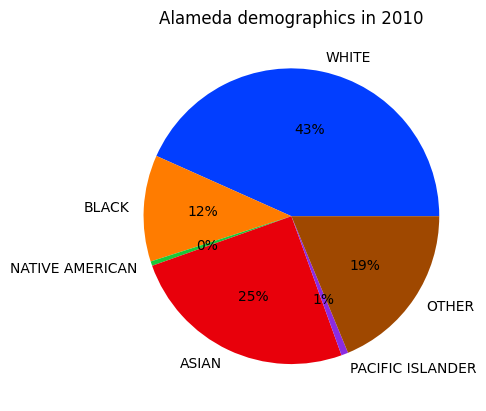

In [4]:
print_pie_acs1(2010, "Alameda")

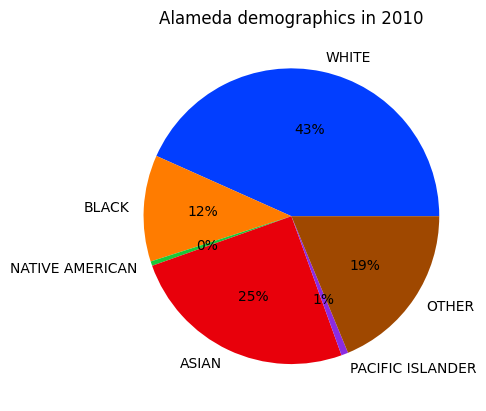

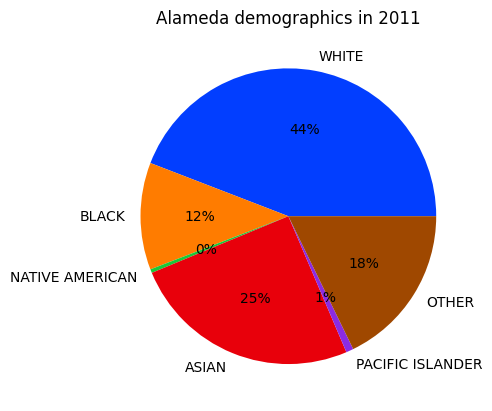

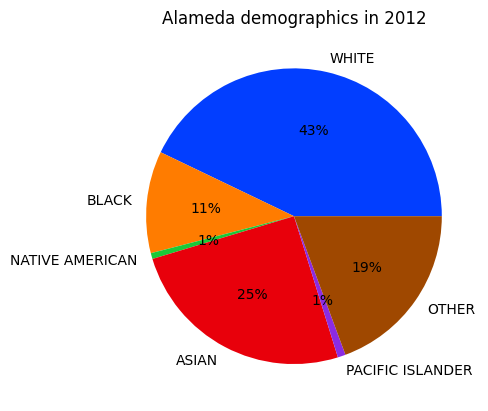

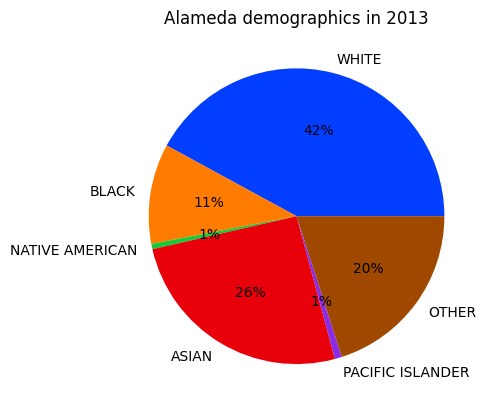

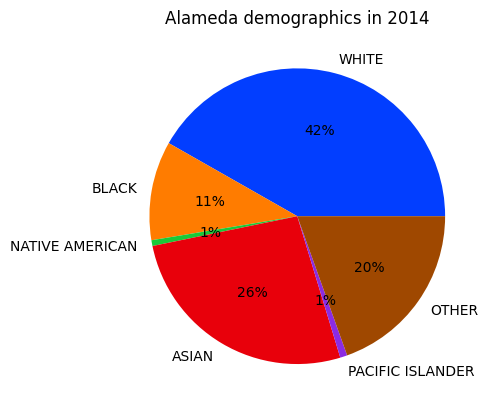

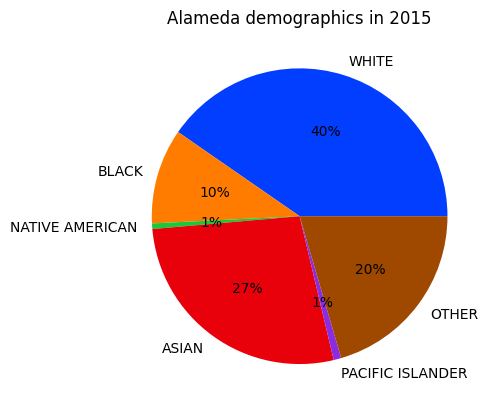

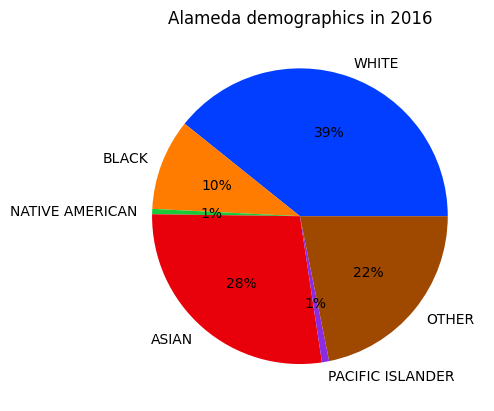

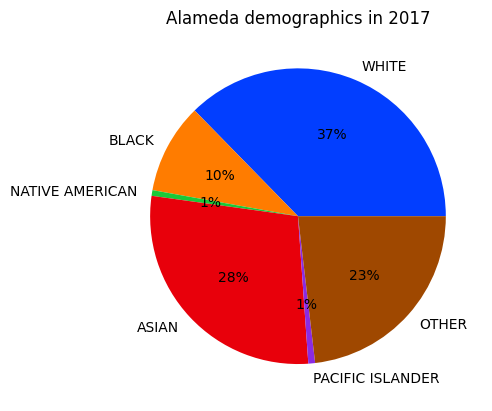

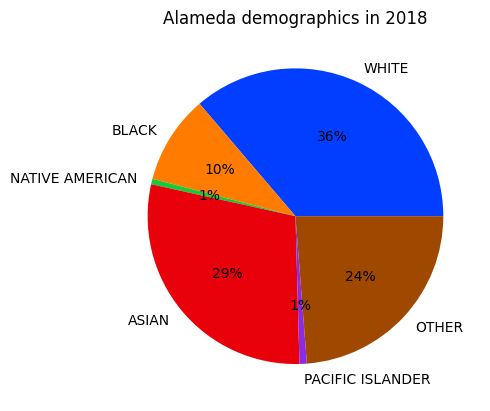

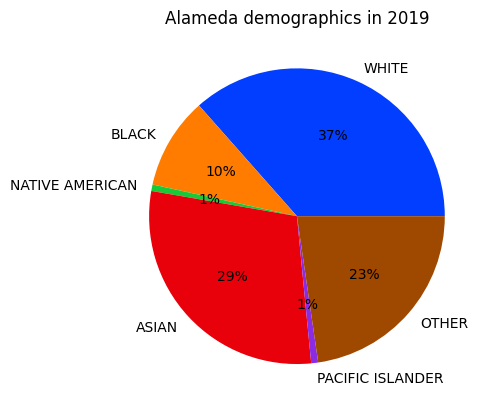

acs1 data not available for 2020


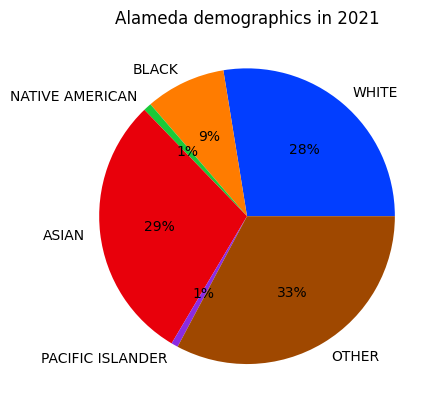

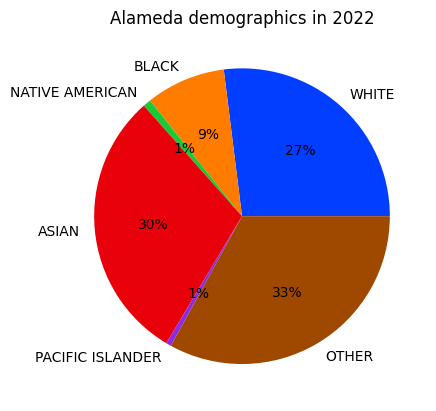

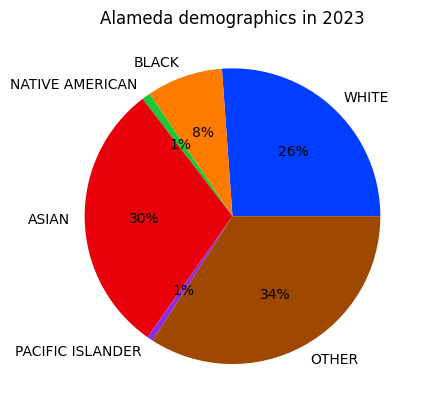

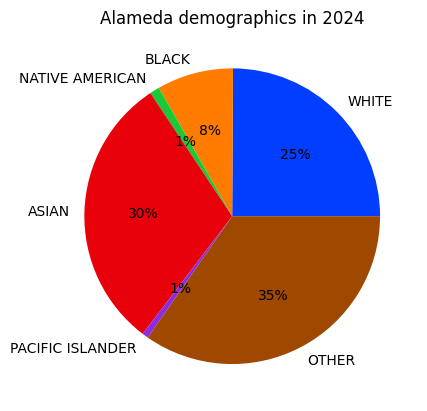

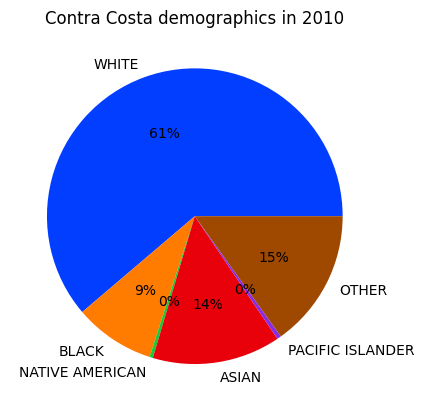

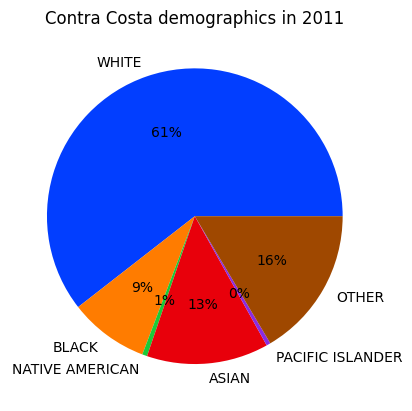

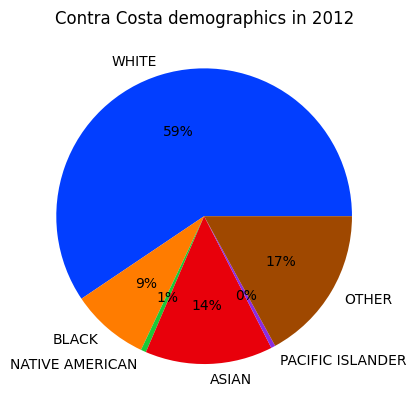

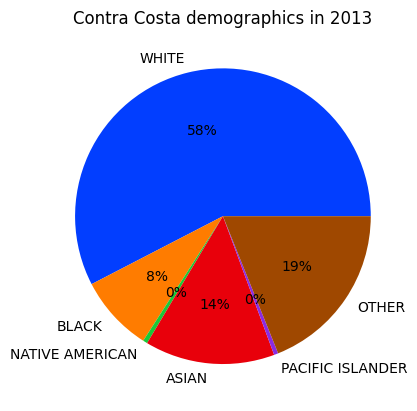

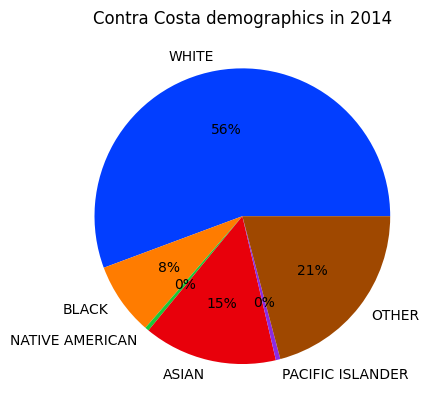

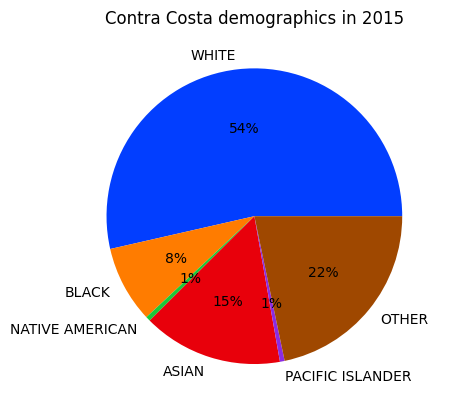

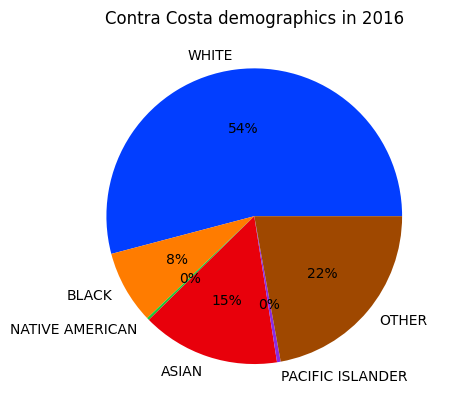

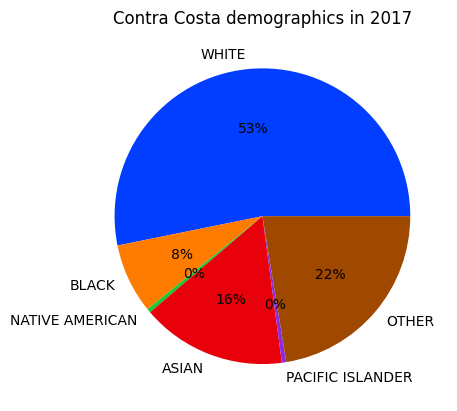

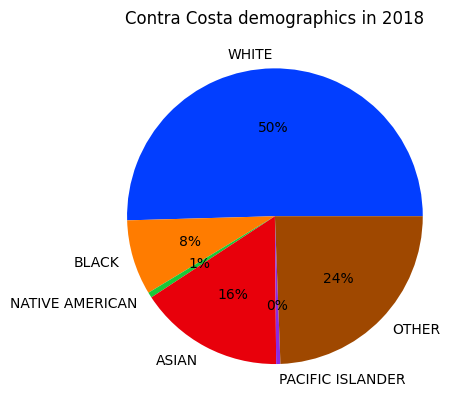

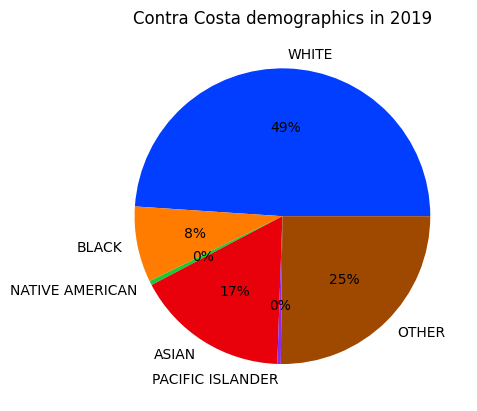

acs1 data not available for 2020


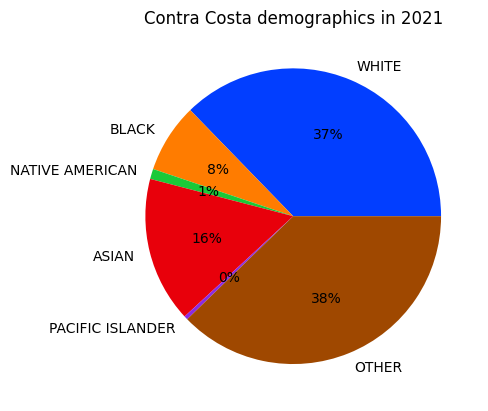

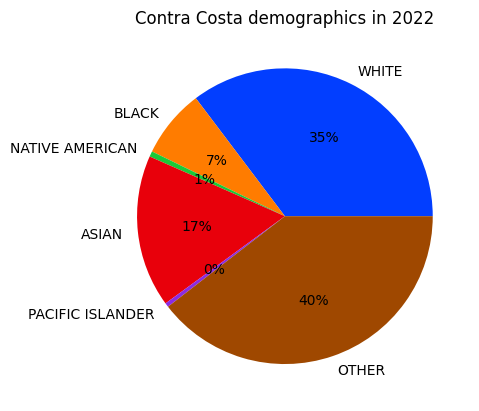

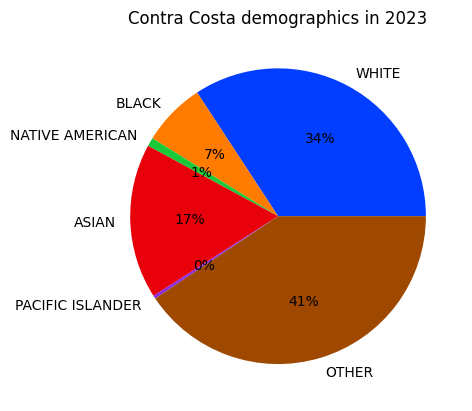

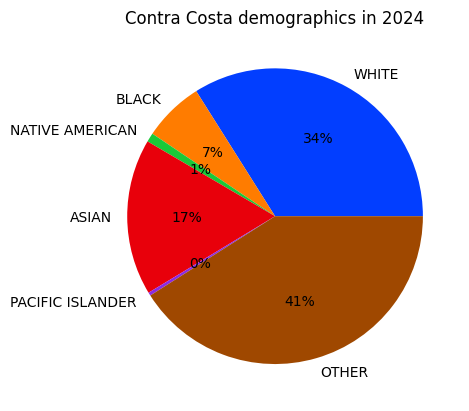

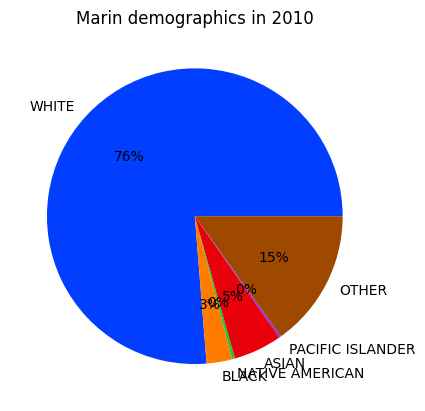

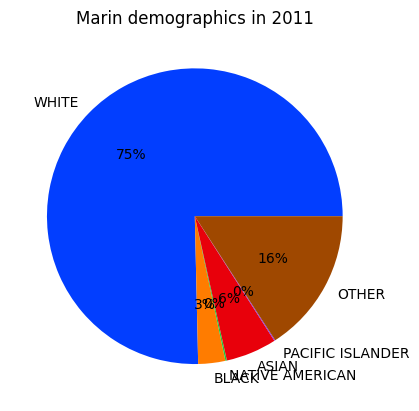

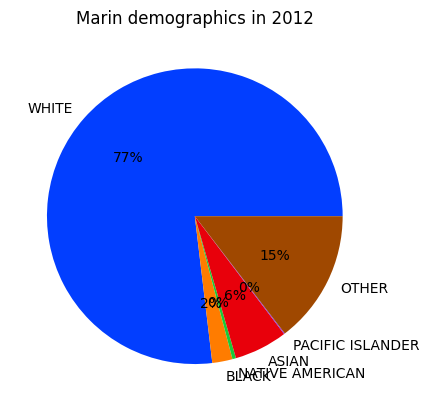

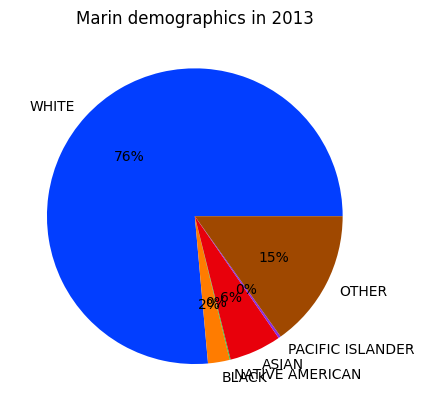

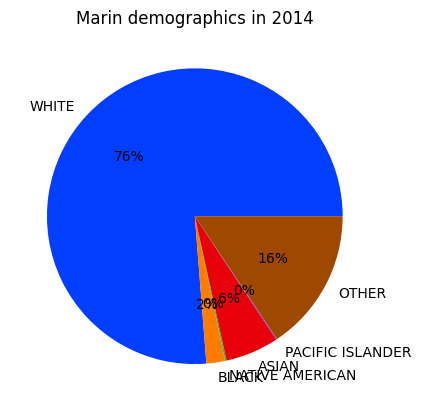

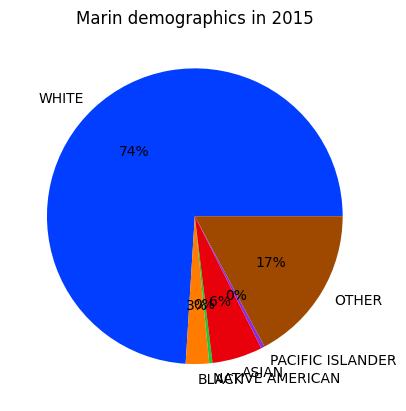

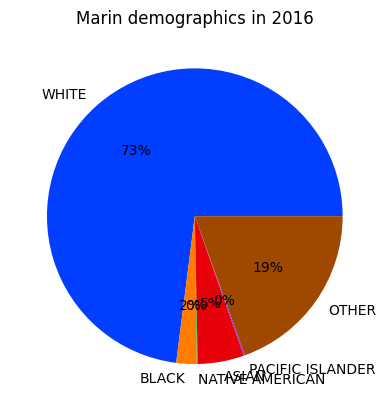

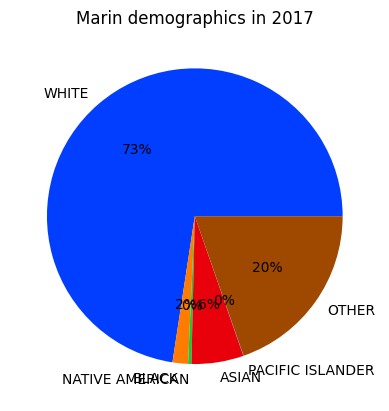

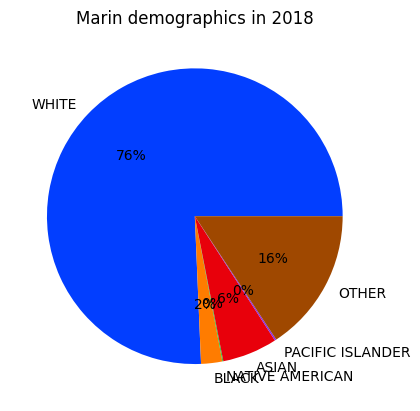

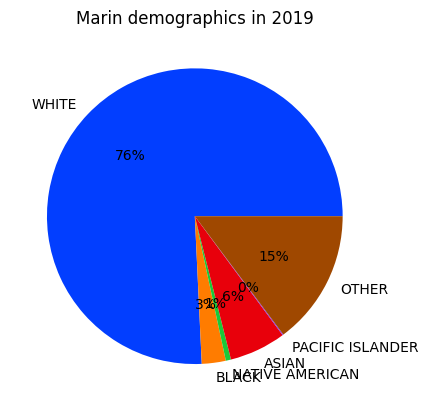

acs1 data not available for 2020


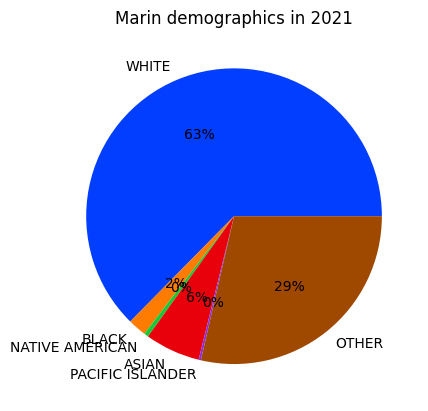

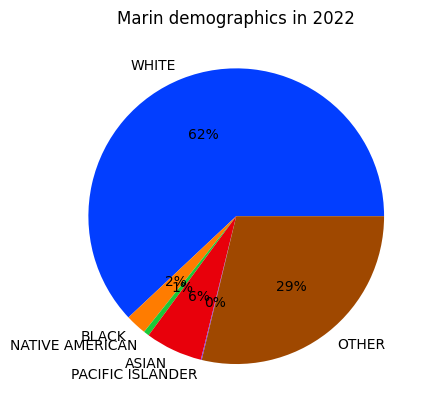

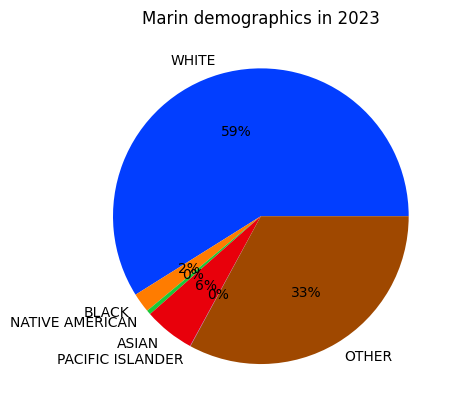

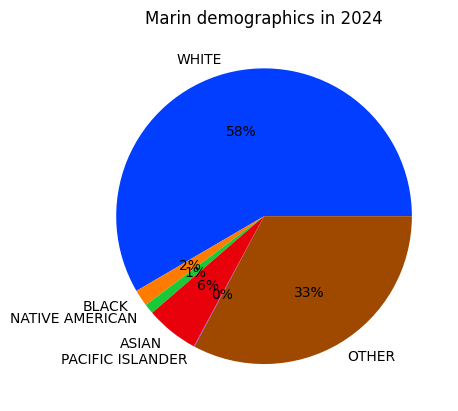

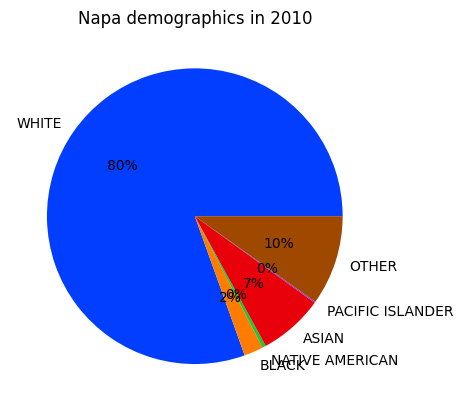

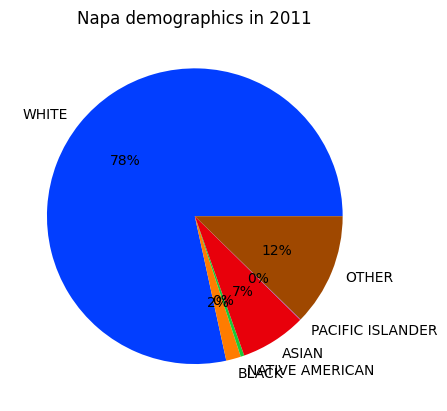

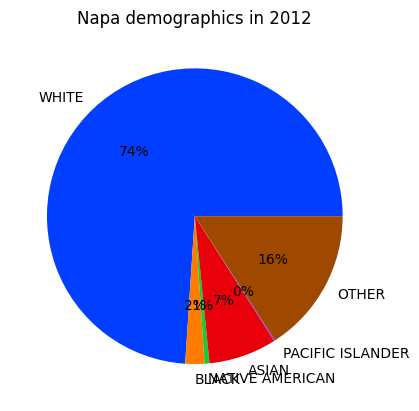

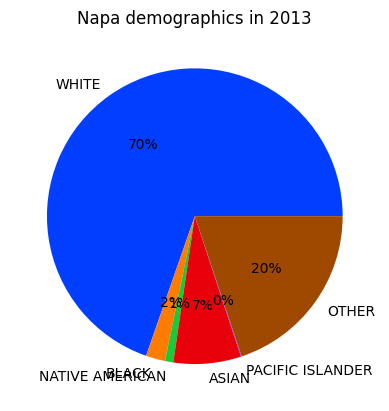

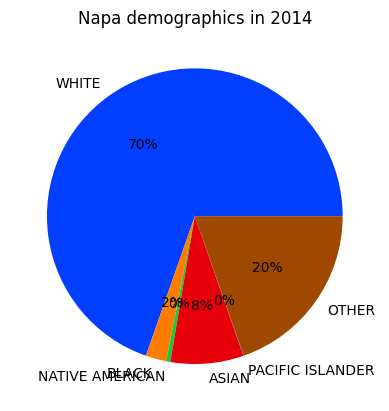

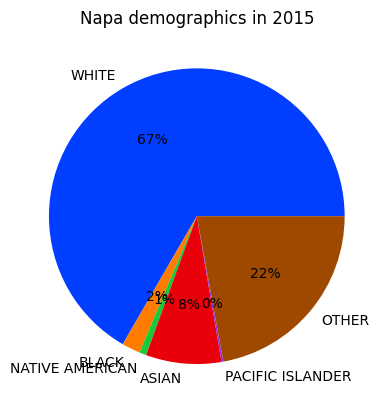

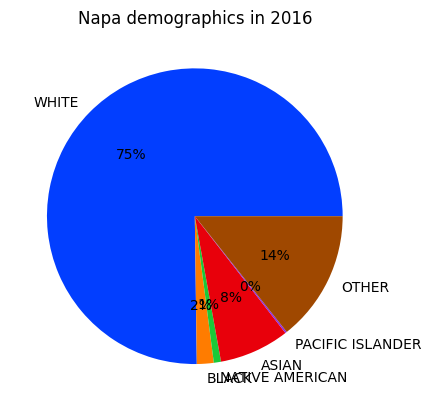

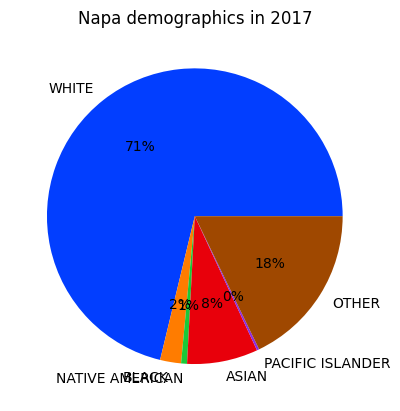

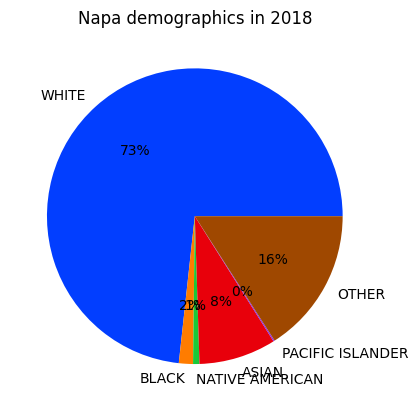

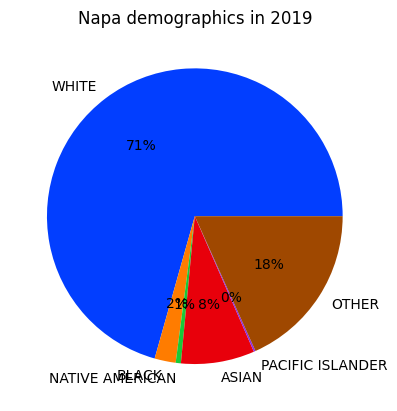

acs1 data not available for 2020


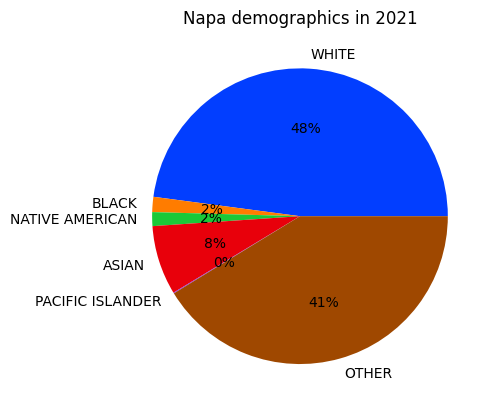

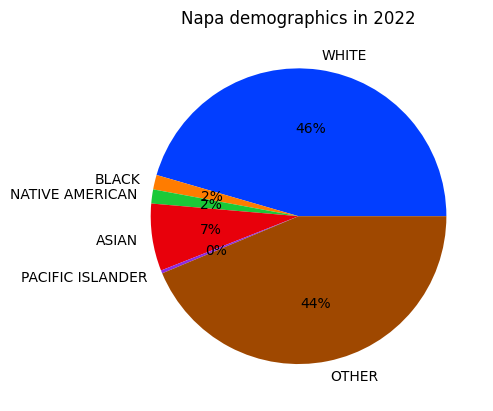

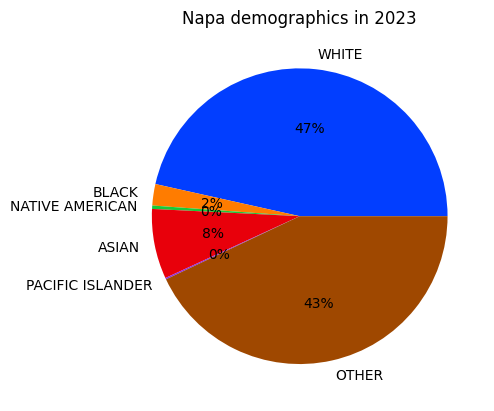

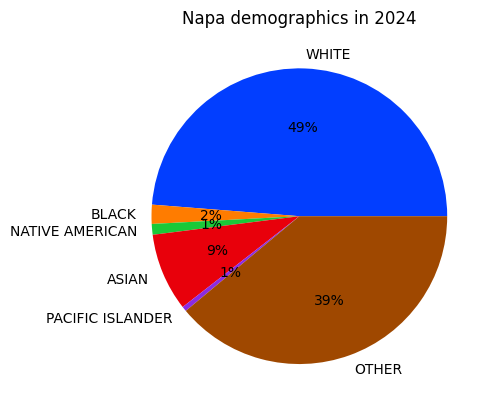

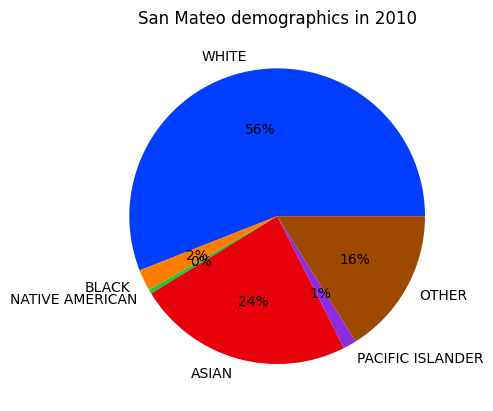

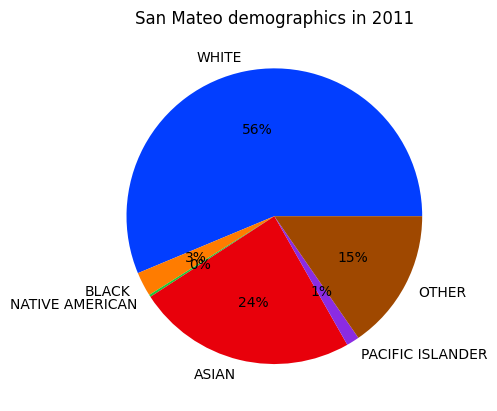

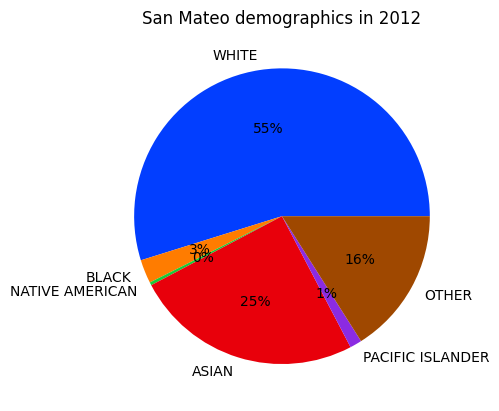

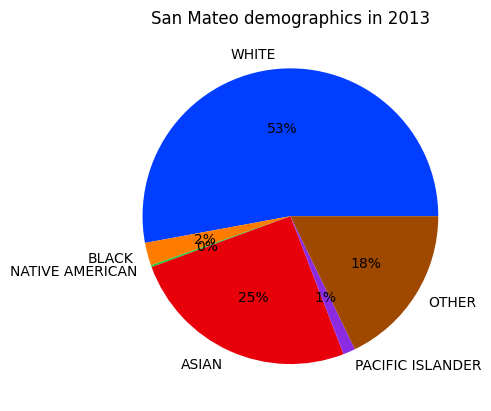

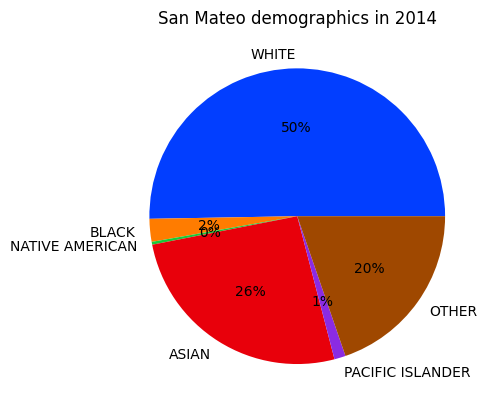

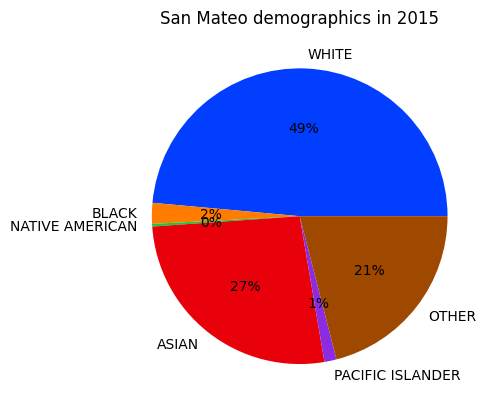

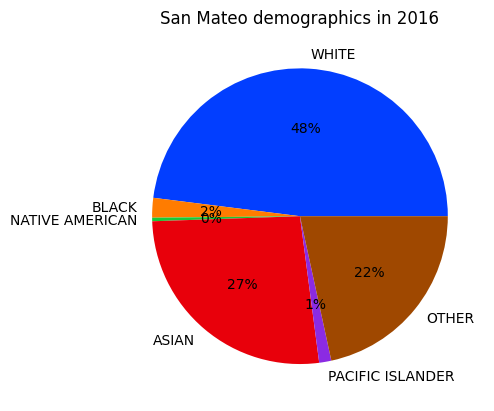

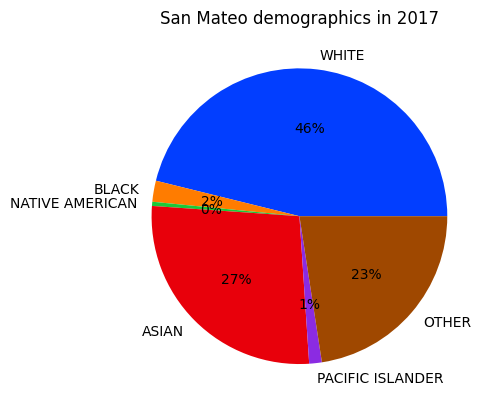

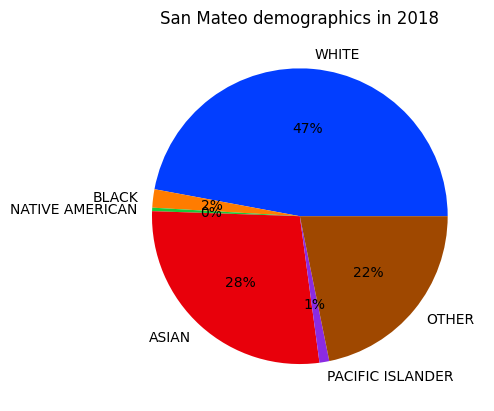

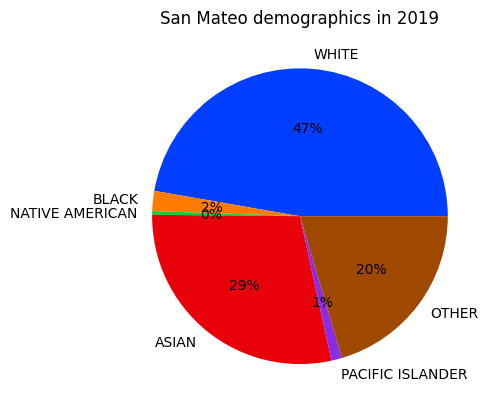

acs1 data not available for 2020


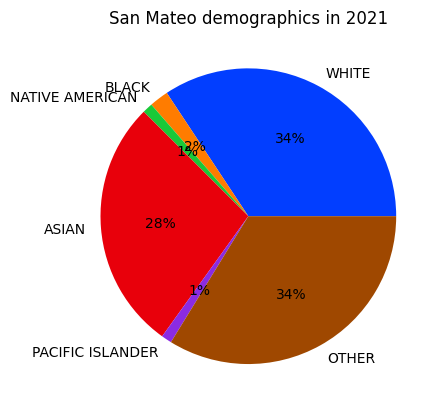

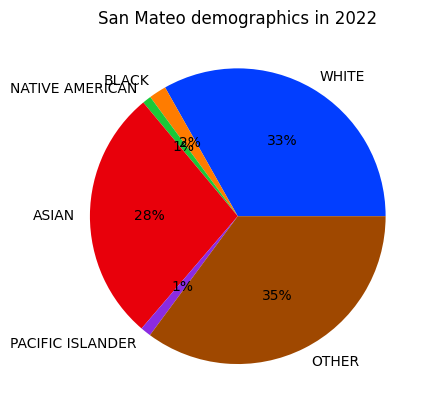

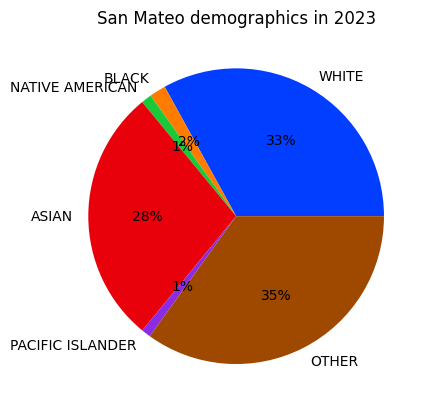

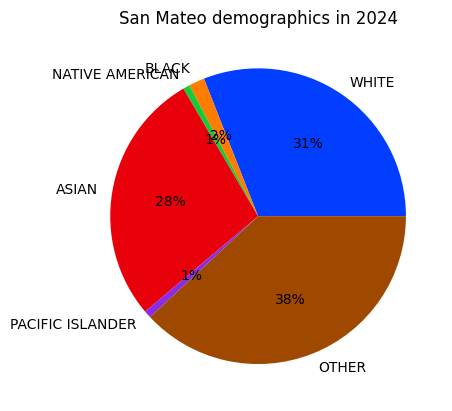

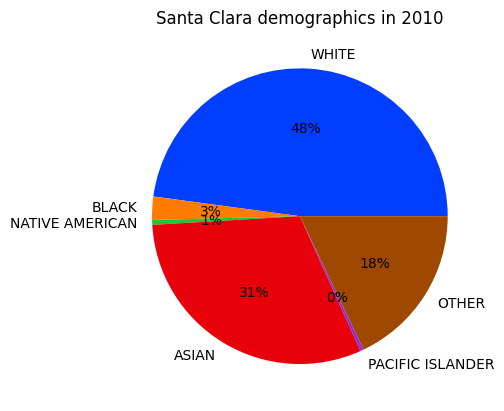

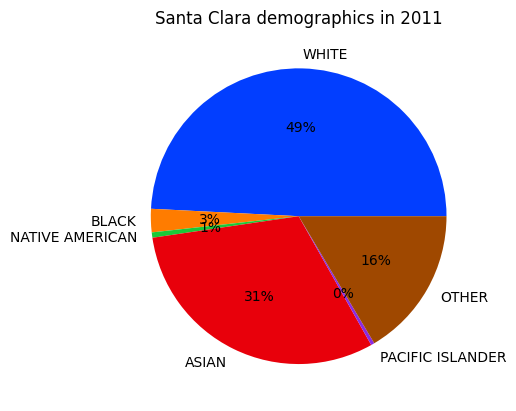

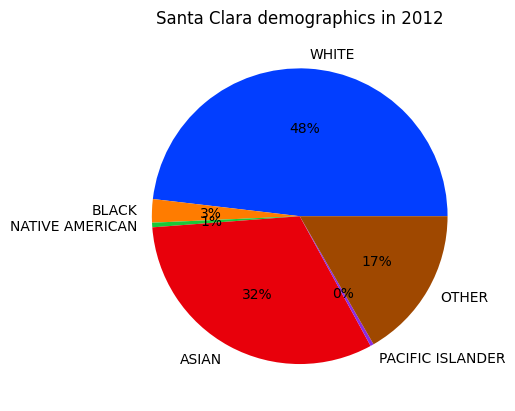

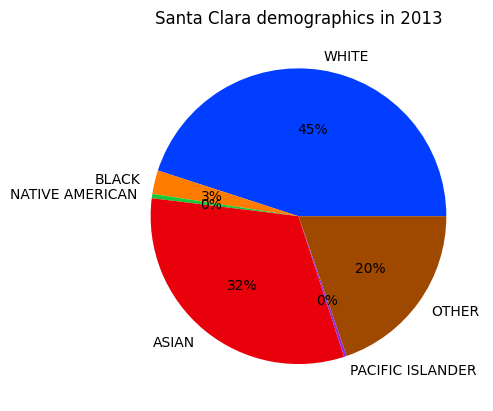

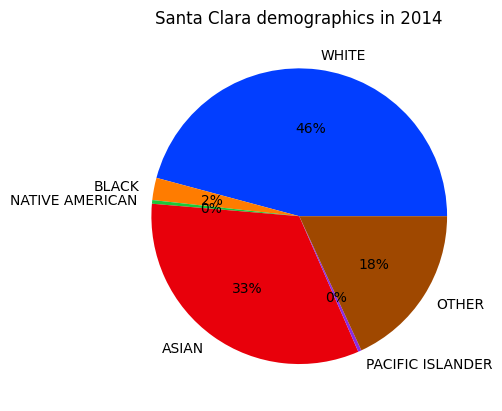

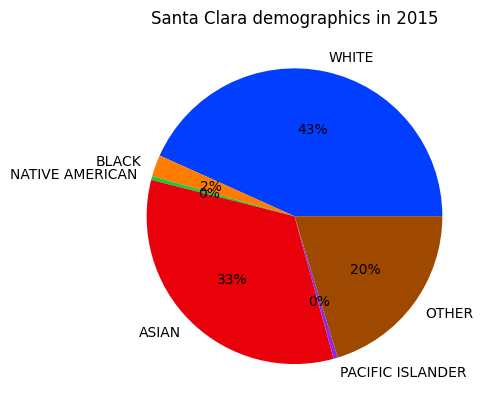

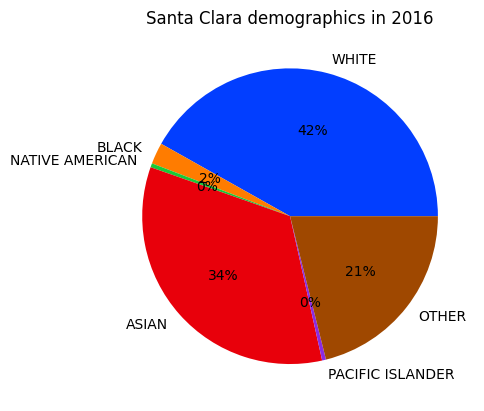

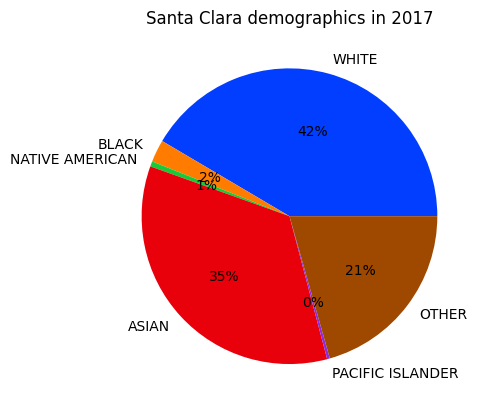

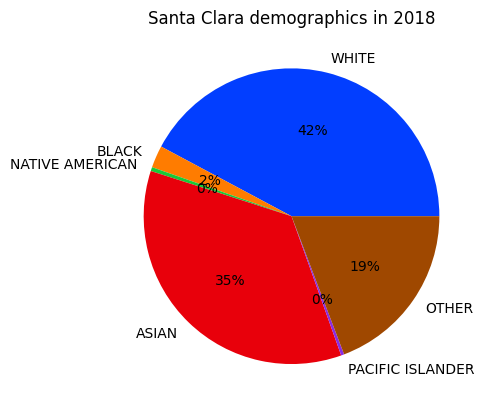

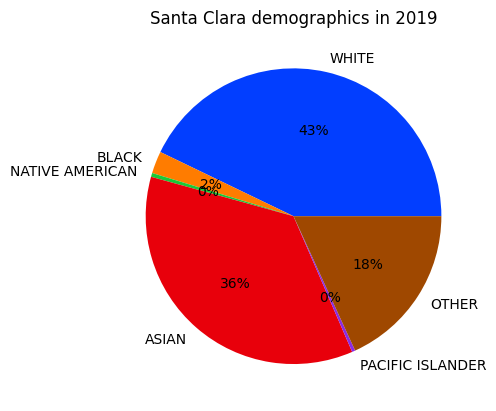

acs1 data not available for 2020


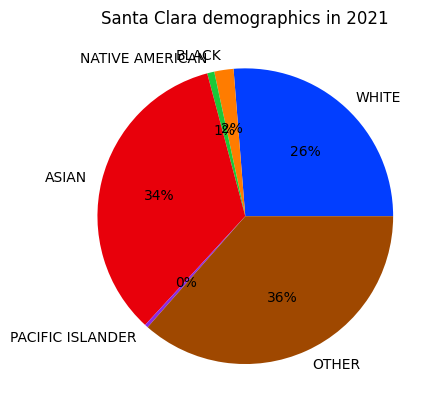

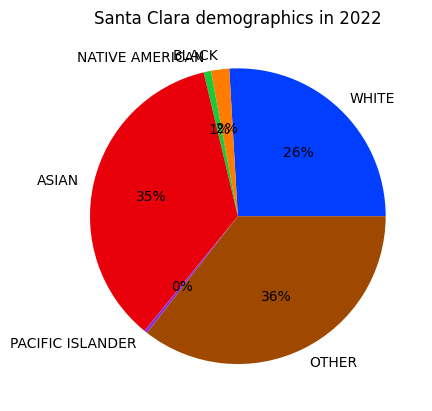

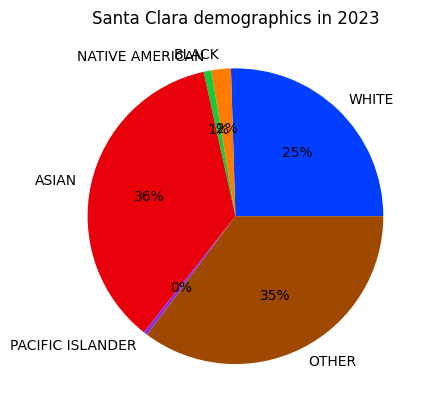

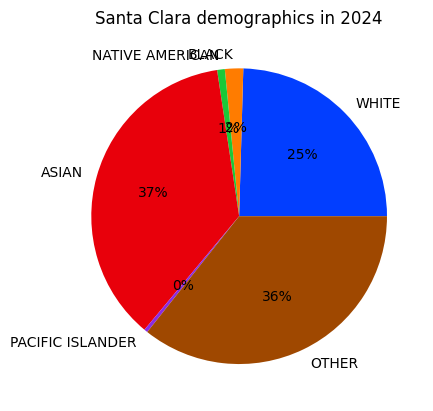

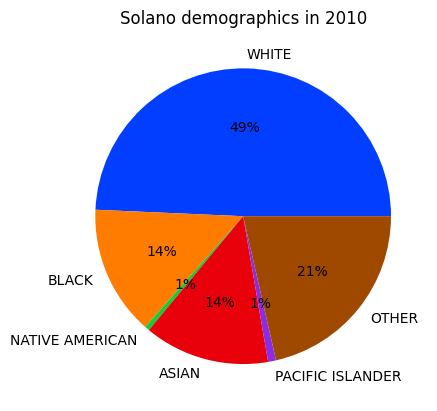

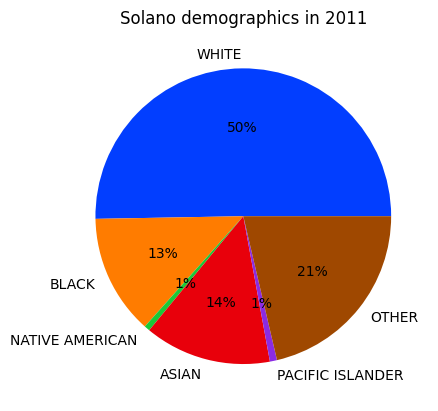

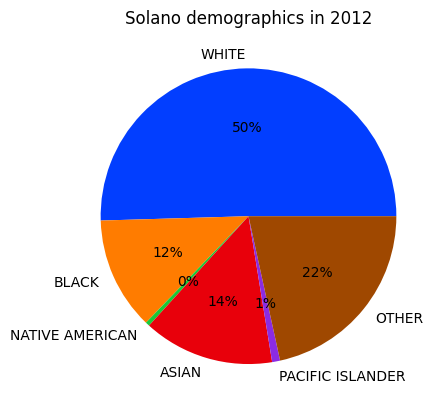

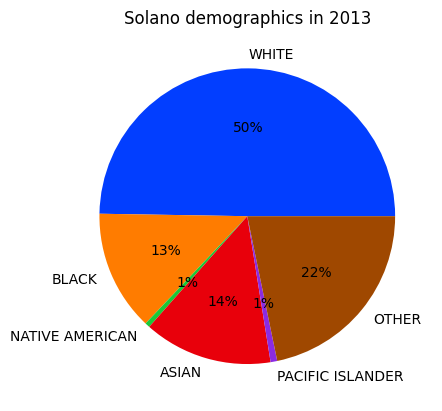

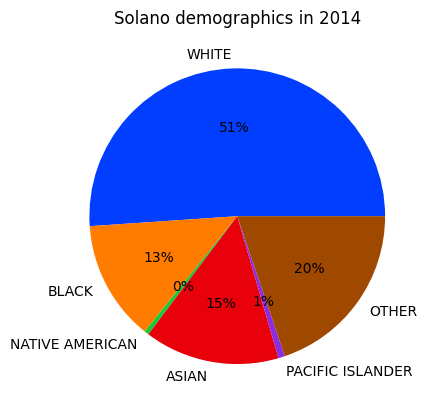

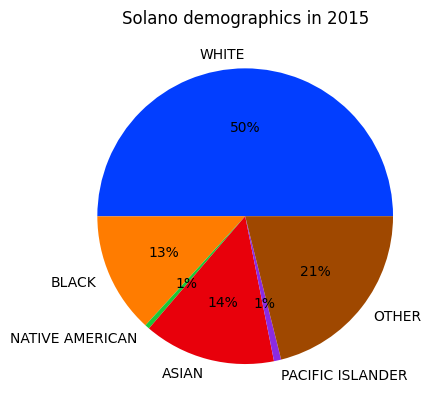

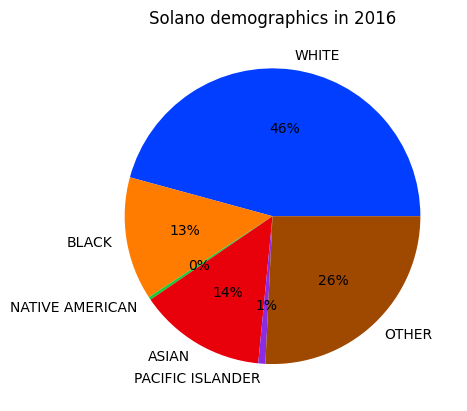

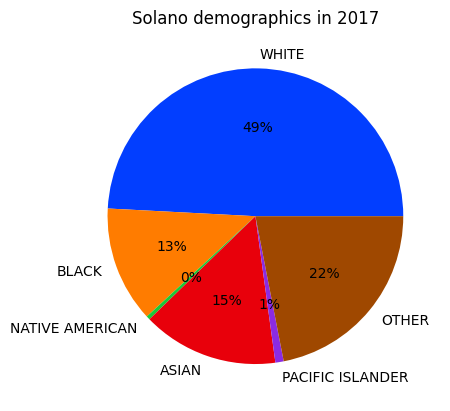

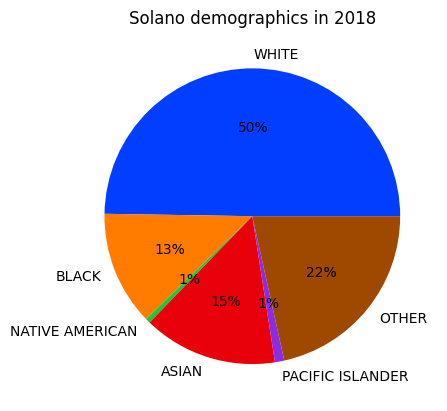

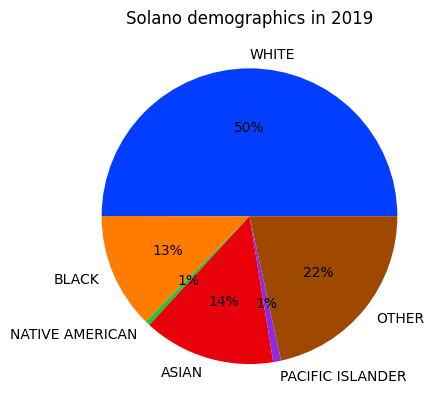

acs1 data not available for 2020


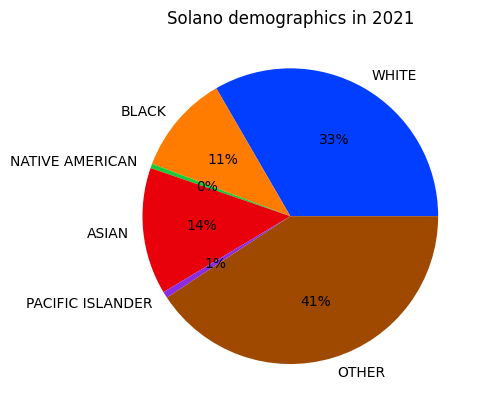

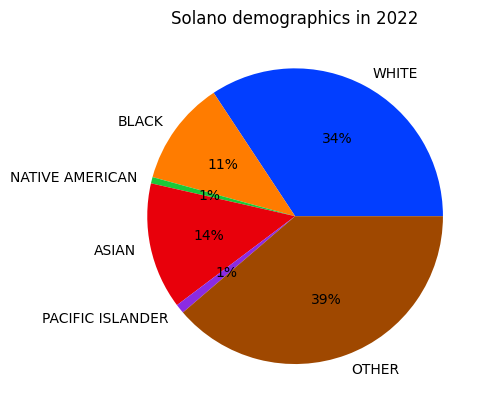

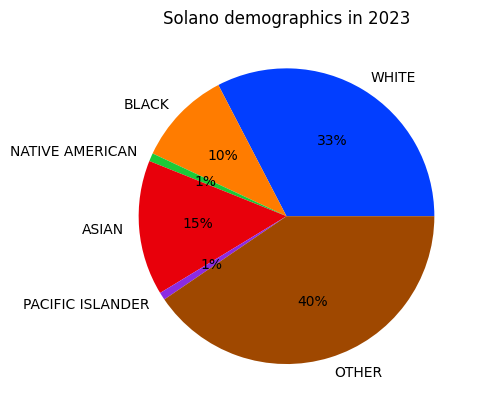

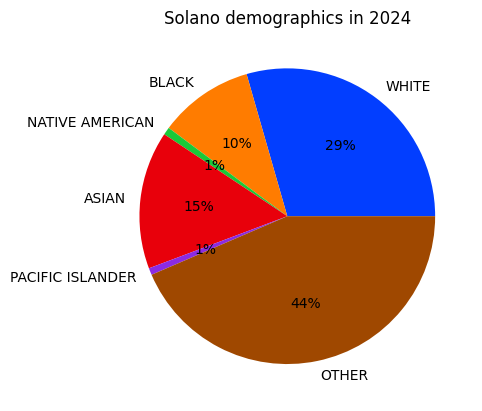

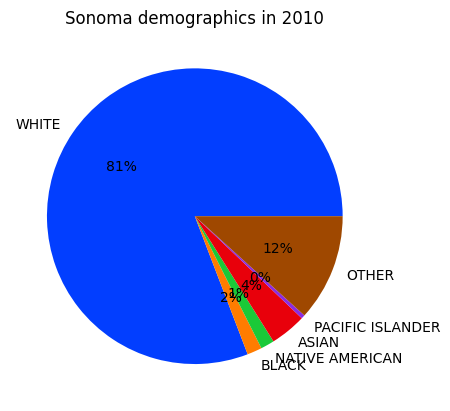

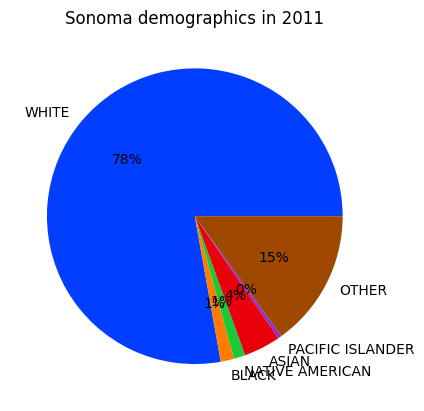

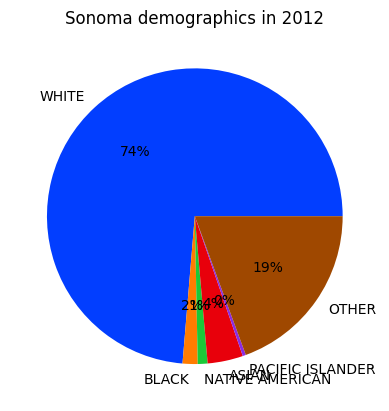

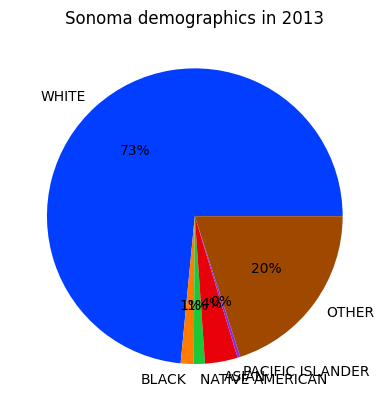

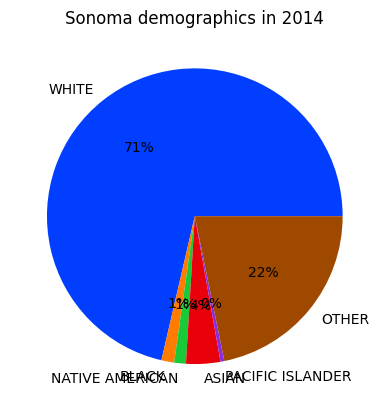

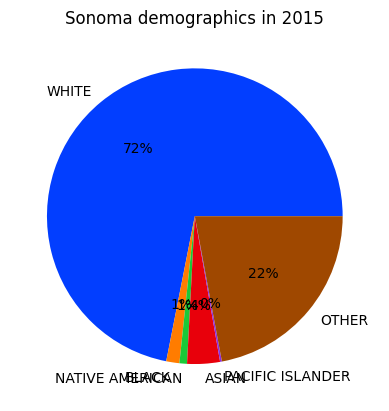

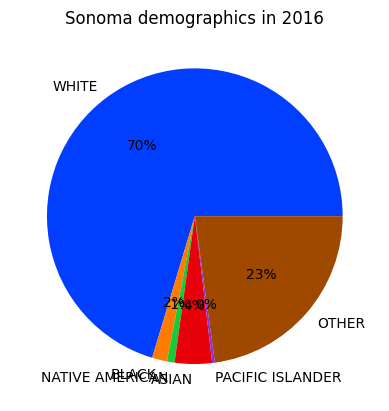

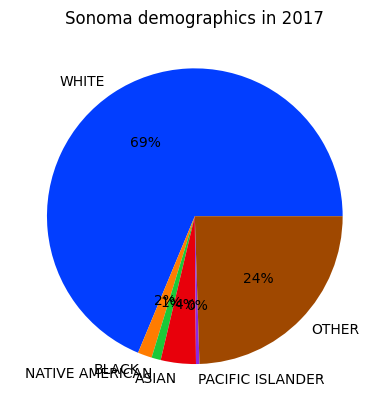

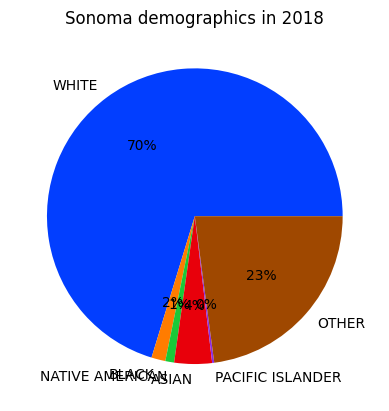

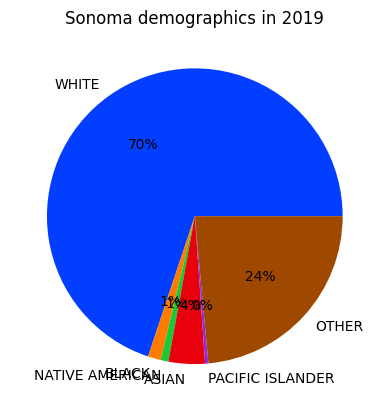

acs1 data not available for 2020


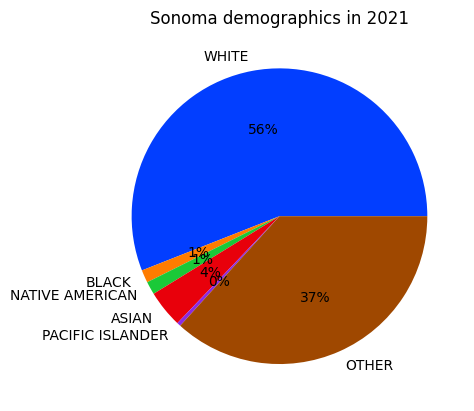

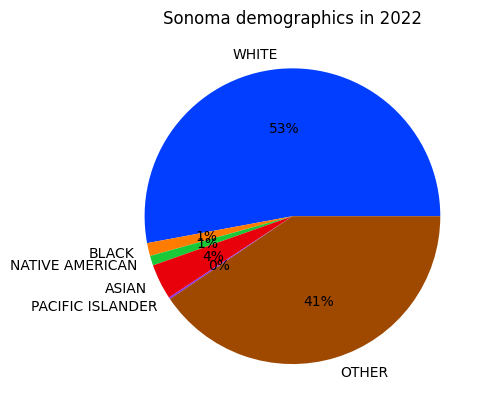

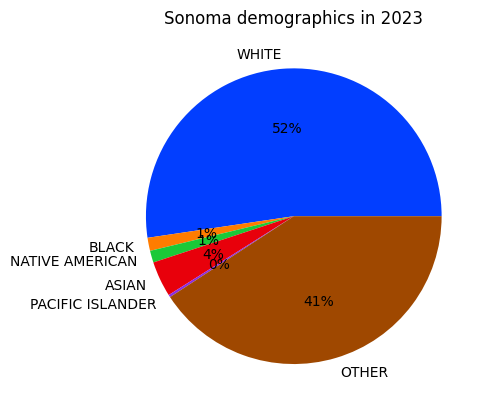

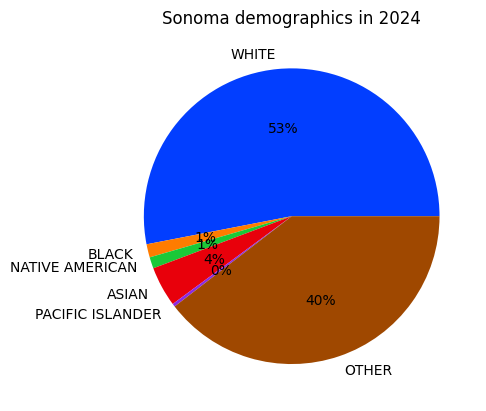

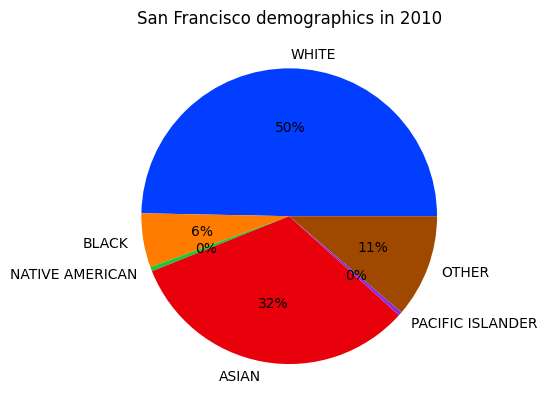

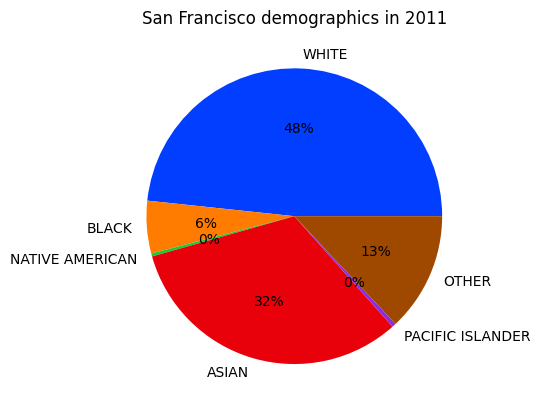

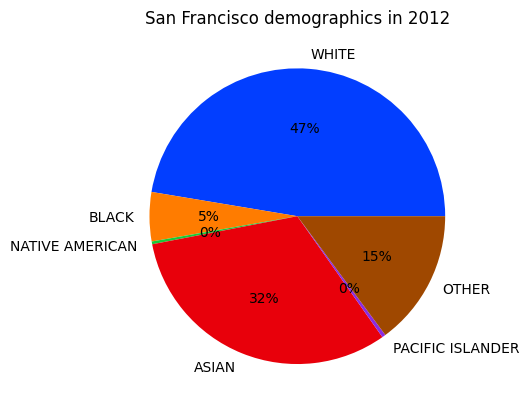

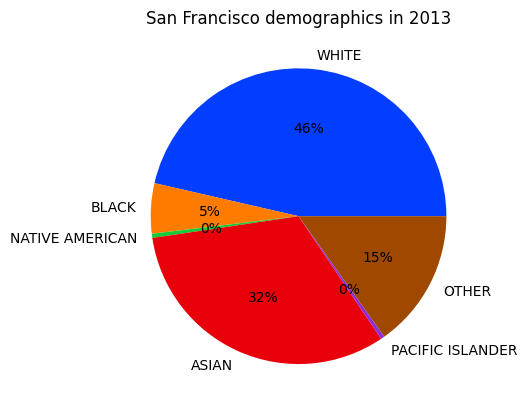

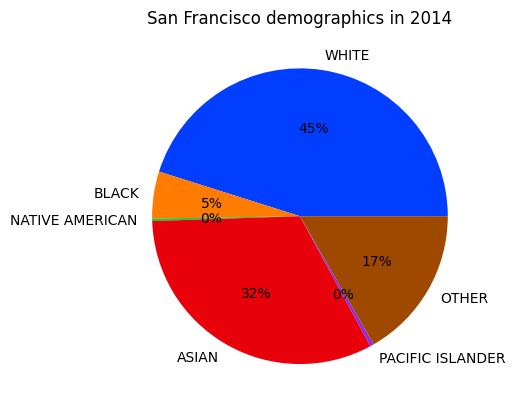

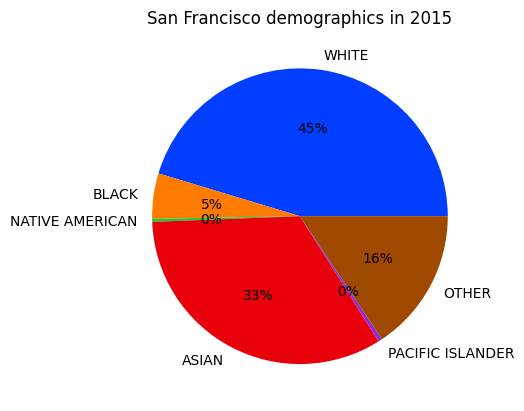

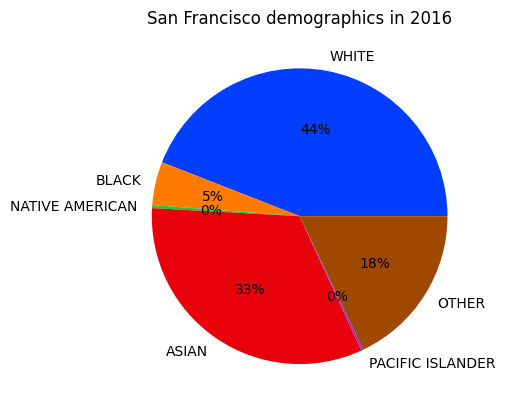

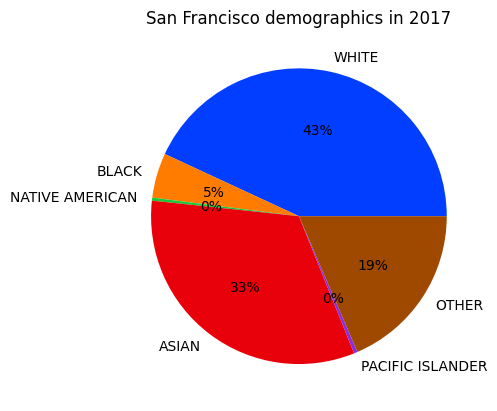

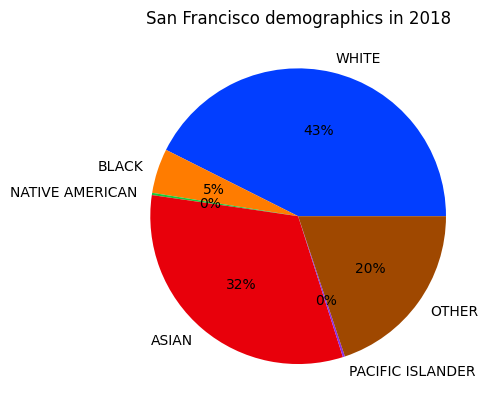

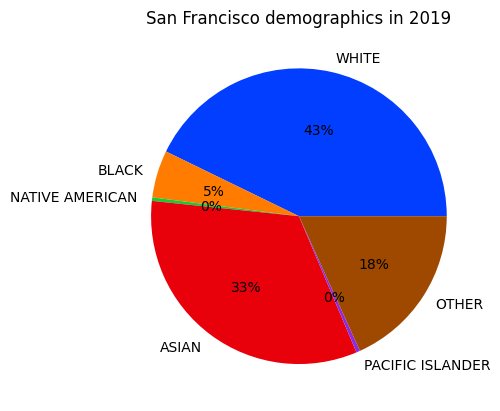

acs1 data not available for 2020


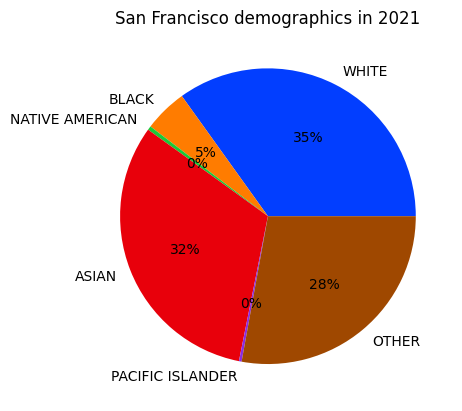

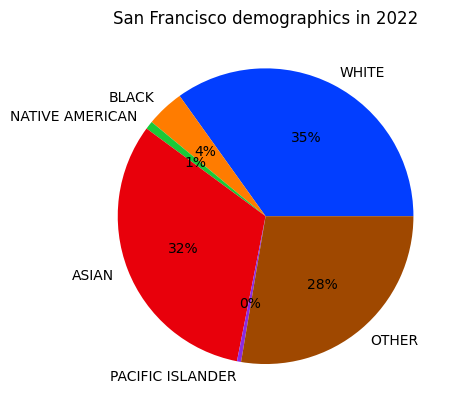

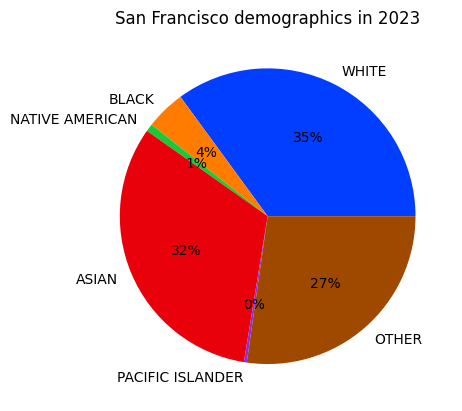

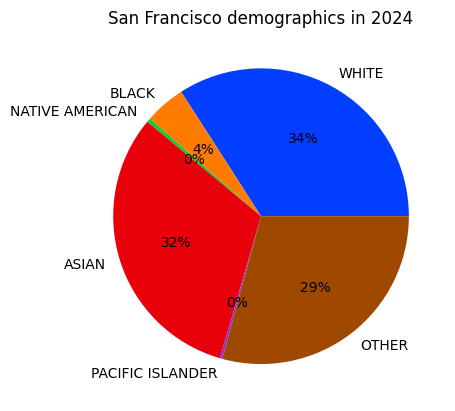

In [5]:
target_counties = ["Alameda", "Contra Costa", "Marin", "Napa", "San Mateo", "Santa Clara", "Solano", "Sonoma", "San Francisco"]

for county in target_counties:
    for year in range(2010, 2025):
        print_pie_acs1(year, county)

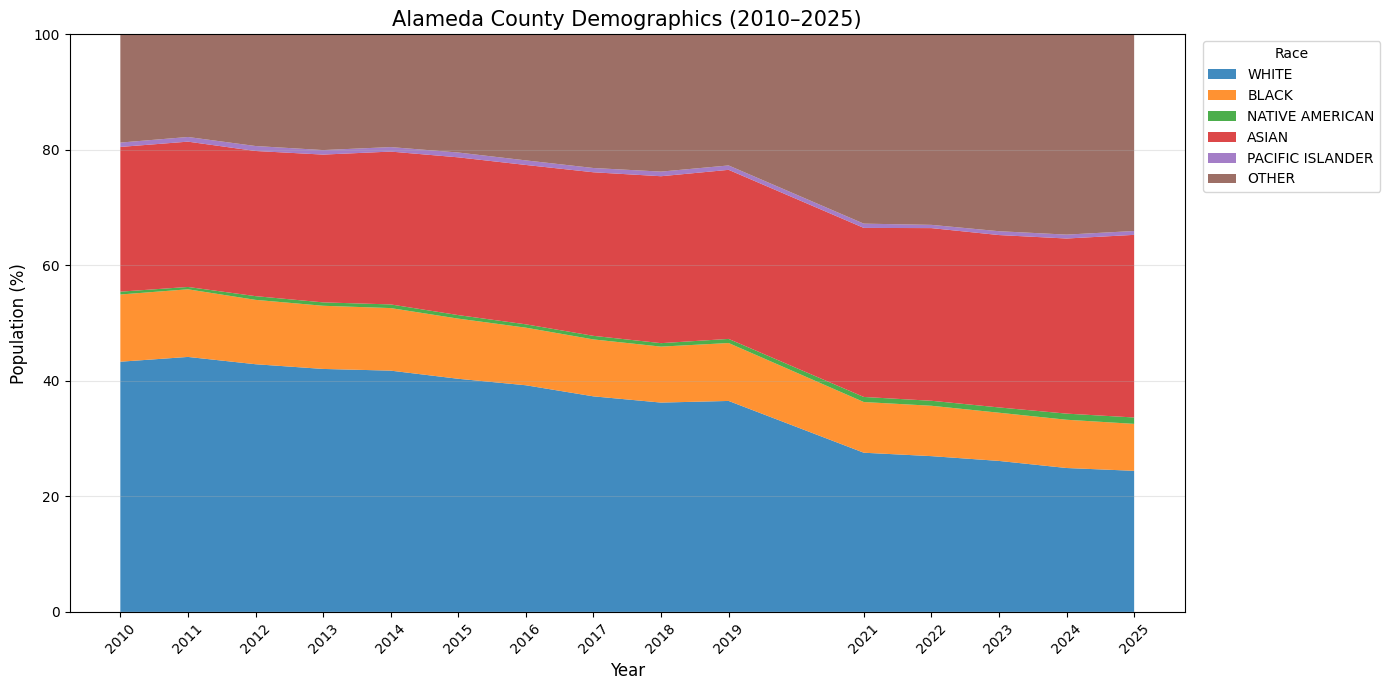

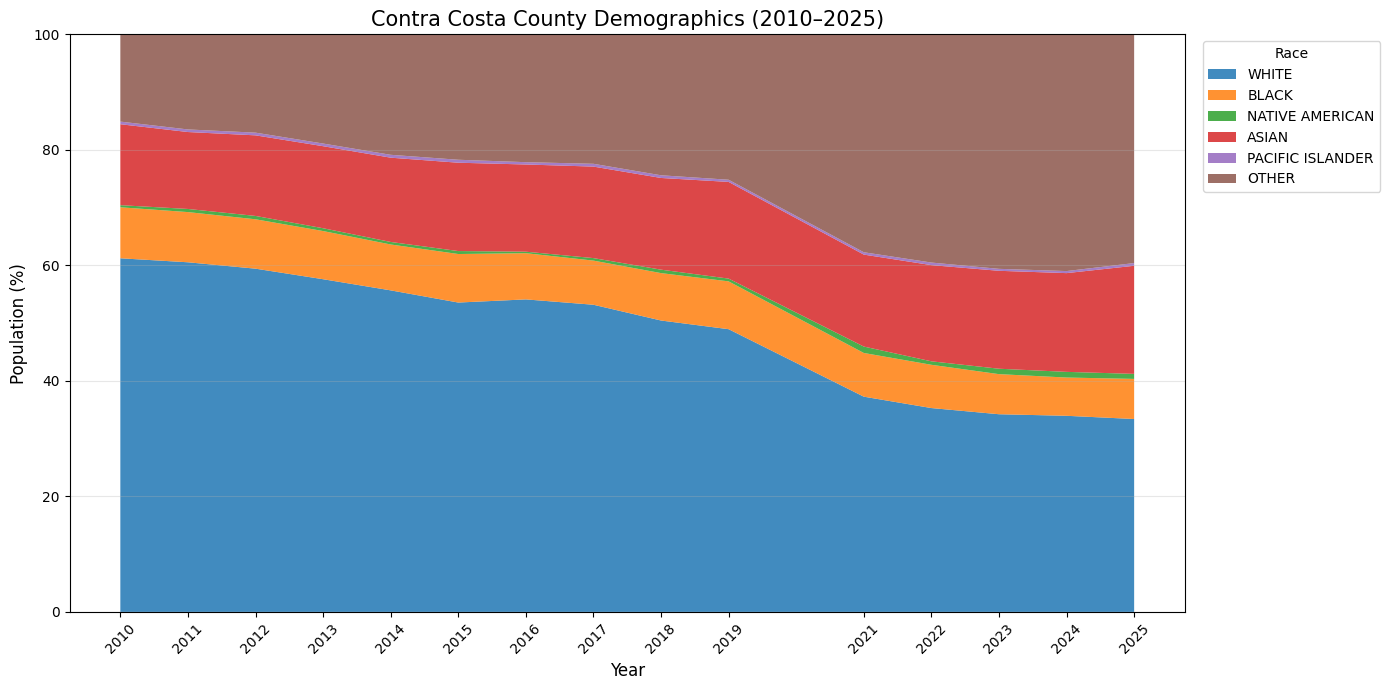

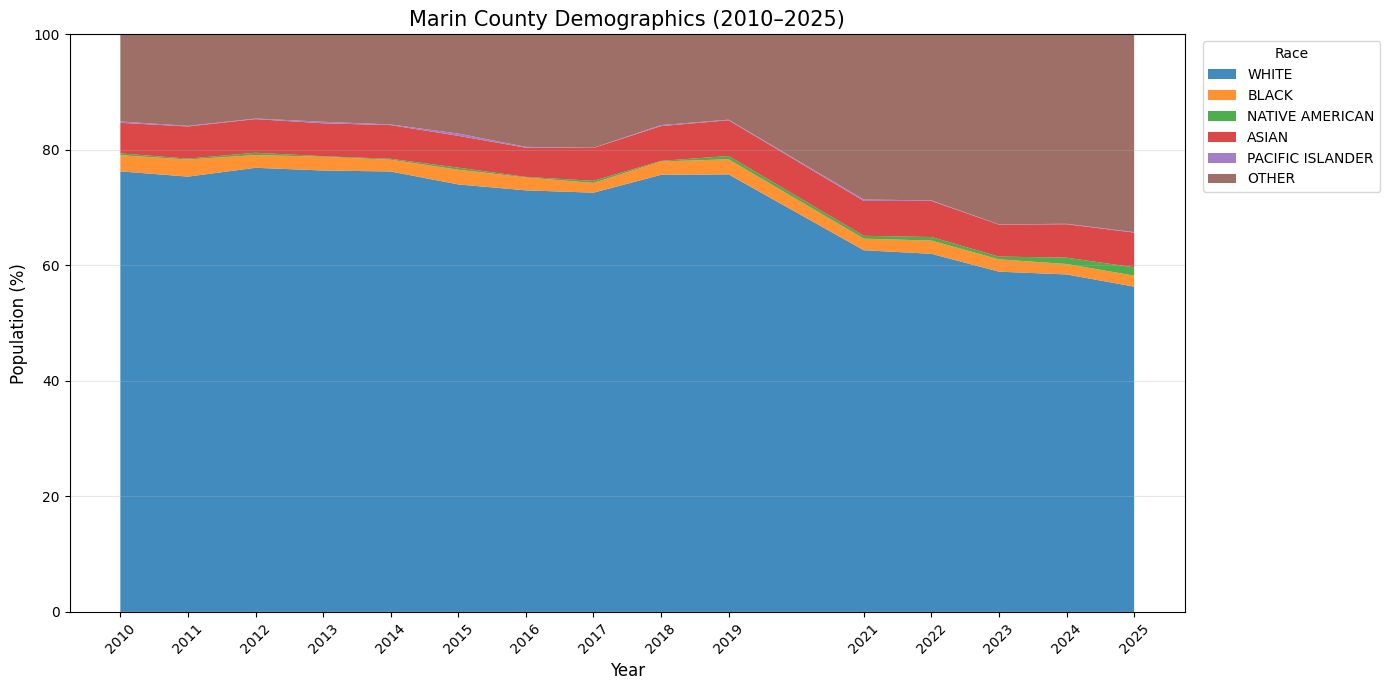

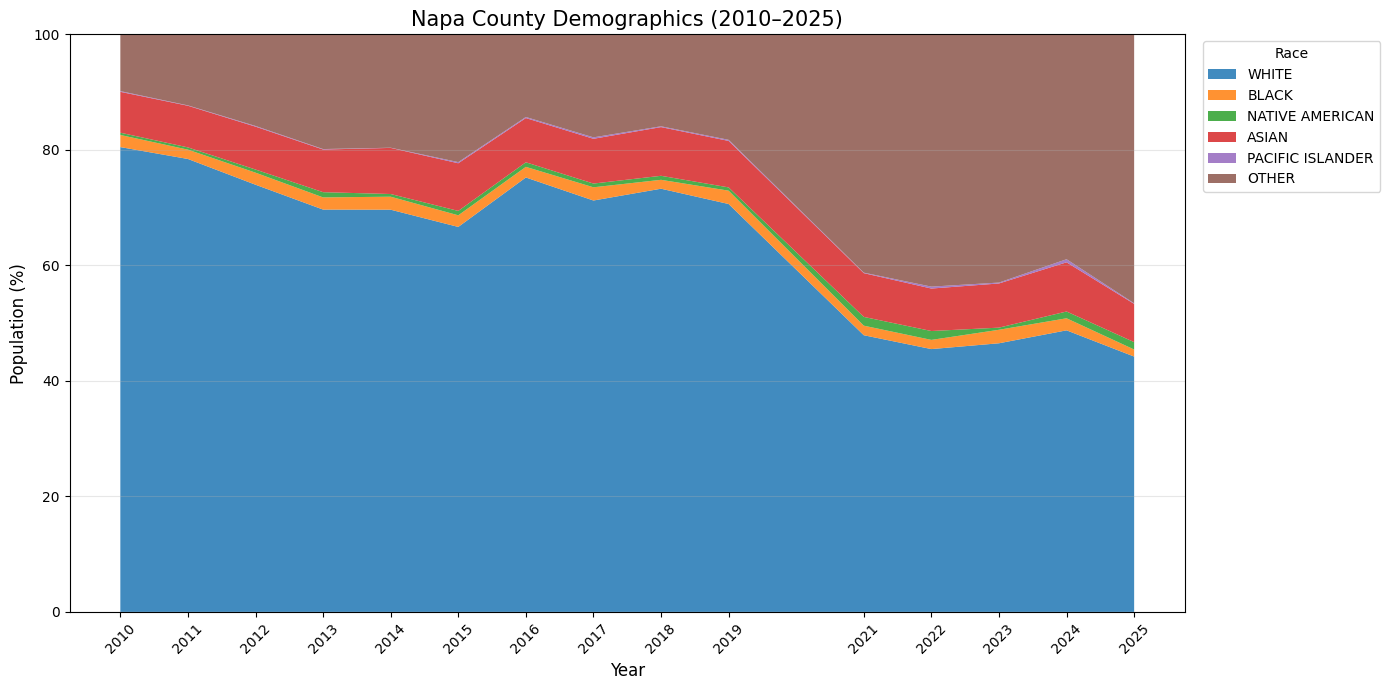

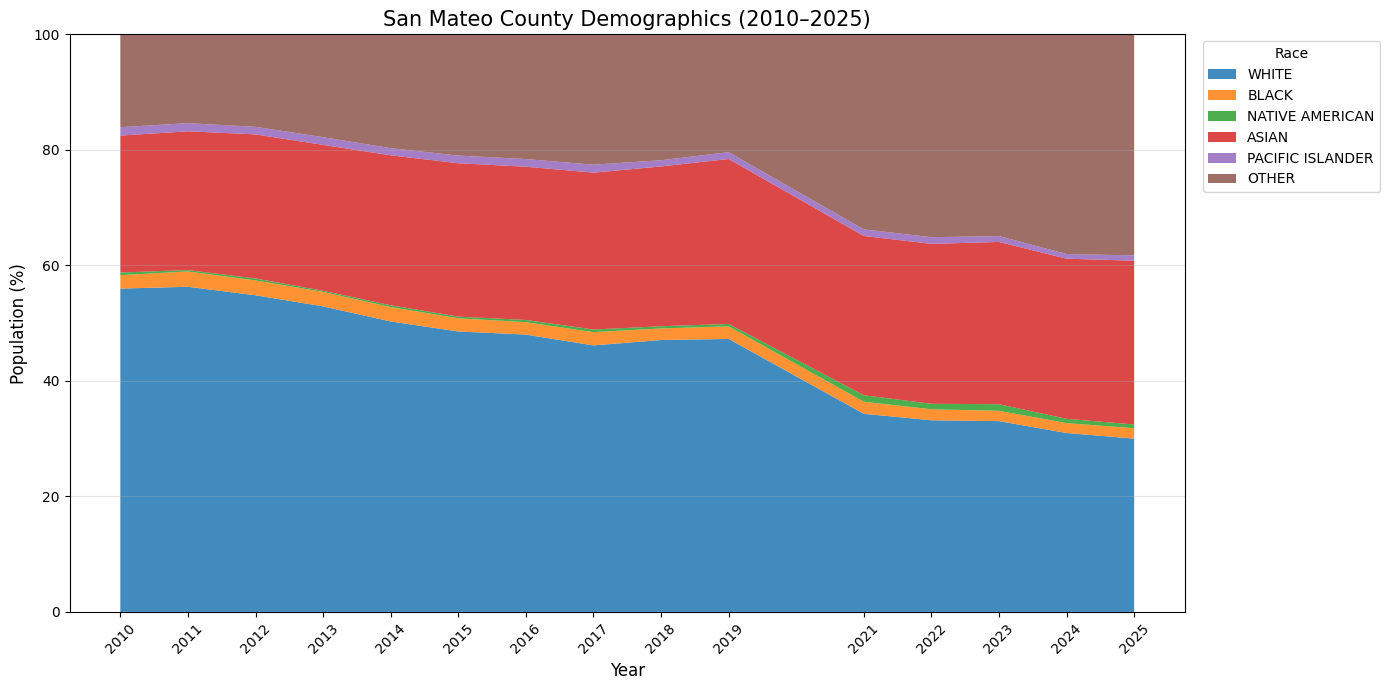

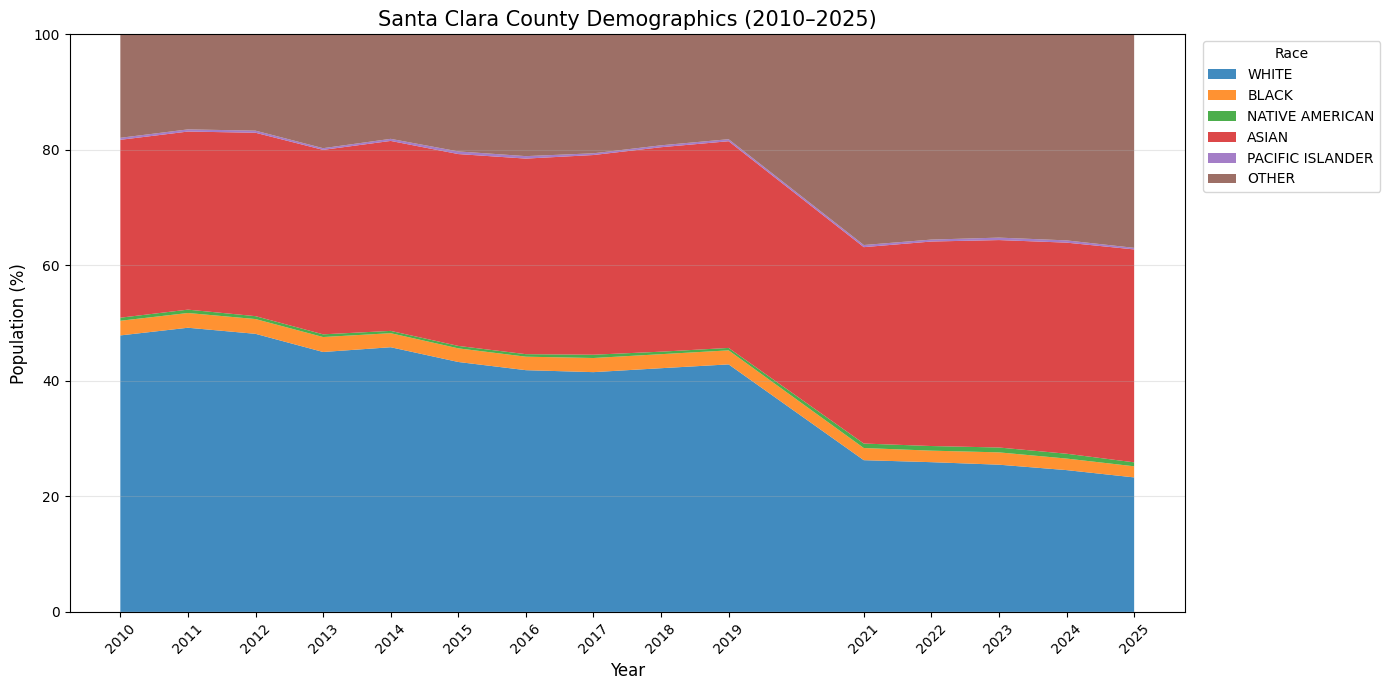

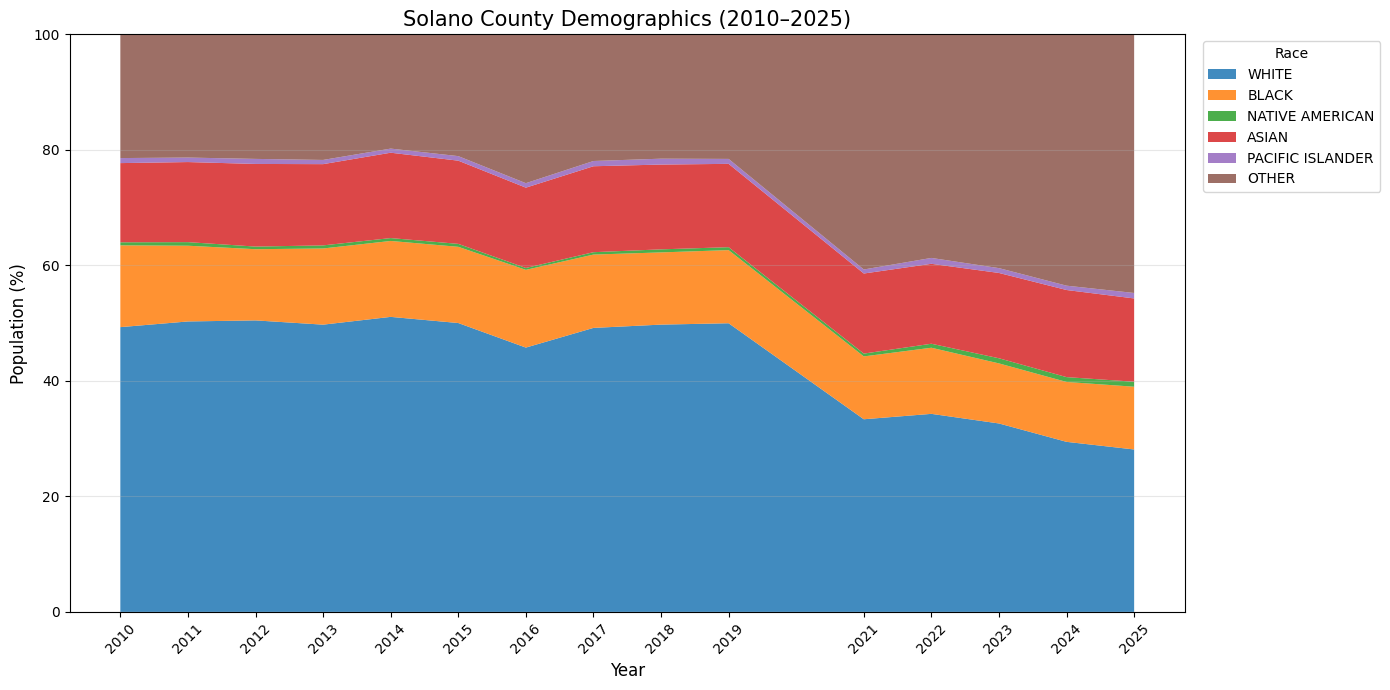

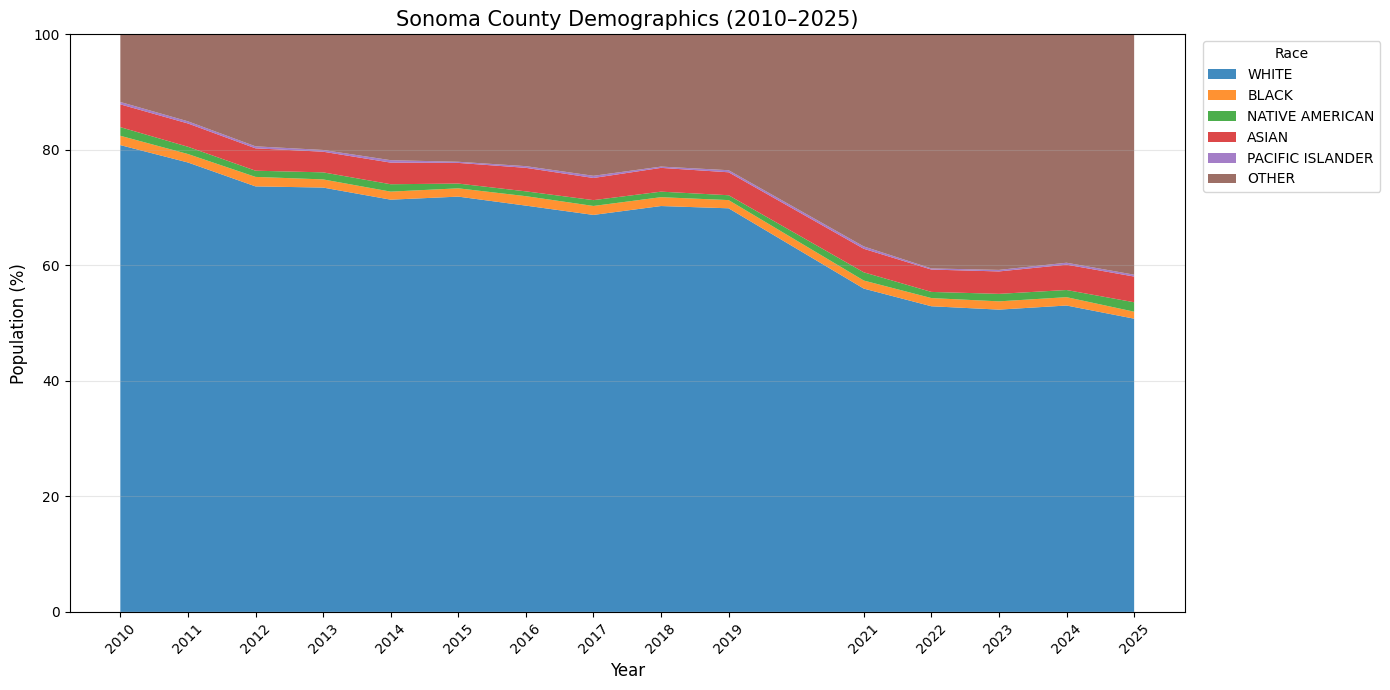

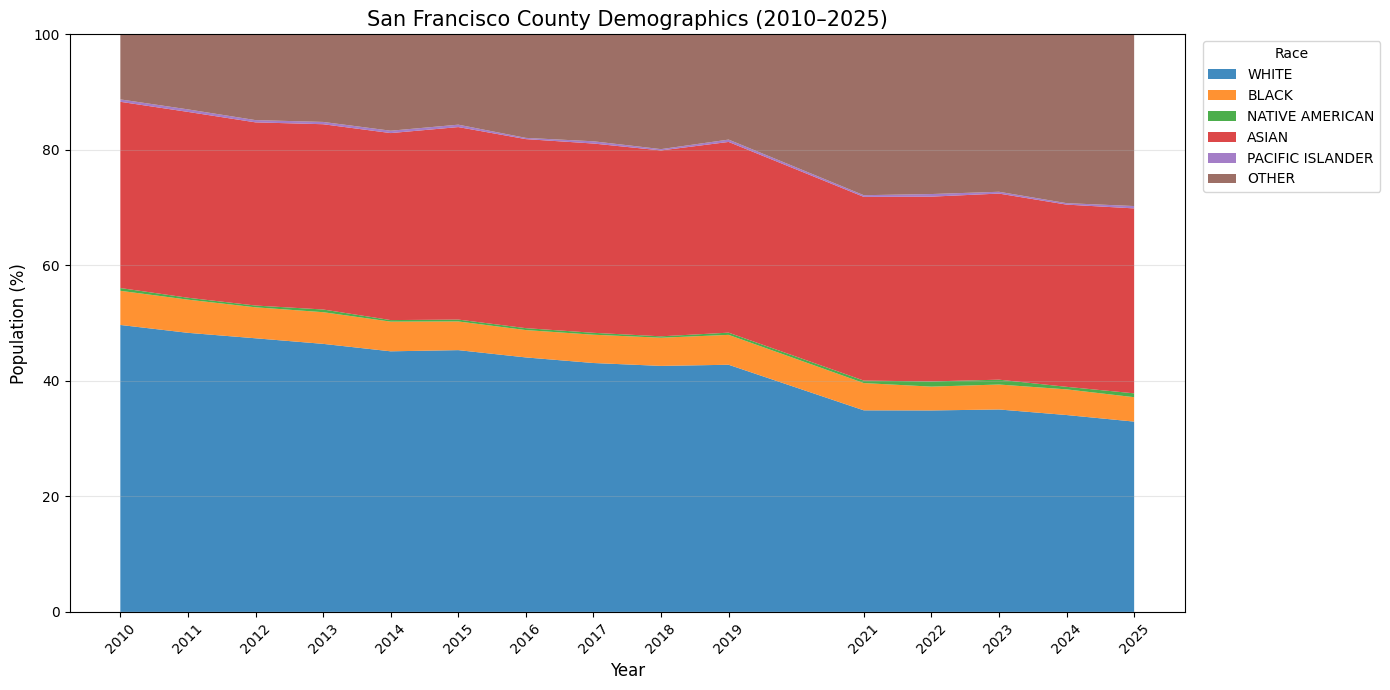

In [6]:
def plot_demographics_over_time(county):
    races = [
        "WHITE",
        "BLACK",
        "NATIVE AMERICAN",
        "ASIAN",
        "PACIFIC ISLANDER",
        "OTHER"
    ]

    # Filter county and exclude 2020 (ACS1 unavailable)
    selected = acs1_combined.loc[
        (acs1_combined["COUNTY"] == county) &
        (acs1_combined["YEAR"] != 2020)
    ].copy()

    # Sort chronologically
    selected = selected.sort_values("YEAR")

    # Calculate percentages
    totals = selected[races].sum(axis=1)

    percentages = selected[races].div(totals, axis=0) * 100

    # Create stacked area chart
    plt.figure(figsize=(14, 7))

    plt.stackplot(
        selected["YEAR"],
        *[percentages[race] for race in races],
        labels=races,
        alpha=0.85
    )

    plt.xlabel("Year", fontsize=12)
    plt.ylabel("Population (%)", fontsize=12)
    plt.title(f"{county} County Demographics (2010–2025)", fontsize=15)

    plt.ylim(0, 100)
    plt.xticks(selected["YEAR"], rotation=45)

    plt.legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        title="Race"
    )

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


for county in target_counties:
    plot_demographics_over_time(county)